# 08 — Robustez por ativo

O experimento é repetido para os sete componentes da carteira. Permanecem
as janelas, as entradas, a configuração da LSTM e o HMM estimado sobre a
carteira. O critério de estresse, portanto, é comum à análise principal.

O alvo passa a ser o log-retorno do ativo em reais. A escala EWMA e o MS-GARCH
também são calculados sobre a série desse ativo.

Os comandos por ativo estão em `scripts/summarize_univariate.py`:
`run_walk_forward.py --target-asset` → `msgarch_inputs.py` →
`r/msgarch_benchmark.R` → `msgarch_forecasts.py` → `evaluate_walk_forward.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
UNI_DIR = PROJECT_ROOT / "reports" / "tables" / "univariado"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})
NAMES = {"hmm_lstm": "HMM-LSTM", "lstm": "LSTM", "zero_mean_reference": "FHS-EWMA", "ms_garch": "MS-GARCH"}
ORDER = list(NAMES.values())
ASSETS = {"SLCE3.SA": "SLC Agrícola", "JBSS32.SA": "JBS", "MBRF3.SA": "Marfrig/MBRF", "SMTO3.SA": "São Martinho",
          "ZS=F": "Soja (BRL)", "KC=F": "Café (BRL)", "BRL=X": "USD/BRL"}

cov = pd.read_csv(UNI_DIR / "resumo_cobertura.csv").assign(
    modelo=lambda t: t.modelo.map(NAMES), ativo=lambda t: t.ativo.map(ASSETS))
dm = pd.read_csv(UNI_DIR / "resumo_dm.csv").assign(
    a=lambda t: t.a.map(NAMES), b=lambda t: t.b.map(NAMES), ativo=lambda t: t.ativo.map(ASSETS))
print(cov.groupby("ativo").n.max().rename("dias de teste").to_string())

ativo
Café (BRL)      2718
JBS             2718
Marfrig/MBRF    2718
SLC Agrícola    2718
Soja (BRL)      2717
São Martinho    2718
USD/BRL         2718


## Taxa de violações por ativo

In [2]:
def rates(segment, level):
    t = cov[(cov.segmento == segment) & (cov.nivel == level)]
    rate = t.pivot(index="ativo", columns="modelo", values="taxa")[ORDER] * 100
    rejected = t.pivot(index="ativo", columns="modelo", values="kupiec_p")[ORDER] < .05
    return rate.round(1).astype(str).where(~rejected, rate.round(1).astype(str) + " *")

for segment in ("todos", "estresse"):
    for level in (.95, .99):
        print(f"\n{segment}, VaR {level:.0%} (% de violações; * = Kupiec rejeita a 5%)")
        display(rates(segment, level).reindex(ASSETS.values()))


todos, VaR 95% (% de violações; * = Kupiec rejeita a 5%)


modelo,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH
ativo,,,,
SLC Agrícola,5.3,5.4,5.5,4.8
JBS,6.9 *,5.7,5.6,4.2 *
Marfrig/MBRF,5.3,5.2,5.5,4.8
São Martinho,5.5,5.8,5.3,4.8
Soja (BRL),5.2,5.6,5.3,4.8
Café (BRL),4.6,5.1,5.2,4.6
USD/BRL,5.9 *,5.5,5.0,4.9



todos, VaR 99% (% de violações; * = Kupiec rejeita a 5%)


modelo,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH
ativo,,,,
SLC Agrícola,1.4 *,1.2,1.2,0.9
JBS,1.7 *,1.4 *,1.2,0.8
Marfrig/MBRF,1.2,1.1,1.2,1.1
São Martinho,1.2,1.2,1.1,1.0
Soja (BRL),1.0,0.9,1.0,0.9
Café (BRL),1.2,1.1,1.2,1.0
USD/BRL,0.9,1.4,1.1,0.9



estresse, VaR 95% (% de violações; * = Kupiec rejeita a 5%)


modelo,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH
ativo,,,,
SLC Agrícola,6.9,7.3,6.6,7.6
JBS,9.3 *,5.5,4.8,4.8
Marfrig/MBRF,8.7 *,7.3,9.3 *,6.2
São Martinho,5.5,6.6,5.2,7.6
Soja (BRL),8.0 *,7.6,8.0 *,6.9
Café (BRL),5.5,5.5,6.2,6.6
USD/BRL,6.9,6.9,7.3,7.3



estresse, VaR 99% (% de violações; * = Kupiec rejeita a 5%)


modelo,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH
ativo,,,,
SLC Agrícola,1.4,1.7,1.7,2.4 *
JBS,1.7,2.4 *,1.7,1.4
Marfrig/MBRF,1.7,2.1,2.1,2.1
São Martinho,2.1,2.4 *,2.1,2.1
Soja (BRL),0.7,0.7,0.7,1.0
Café (BRL),1.4,1.0,1.0,1.0
USD/BRL,1.4,1.4,1.0,1.0


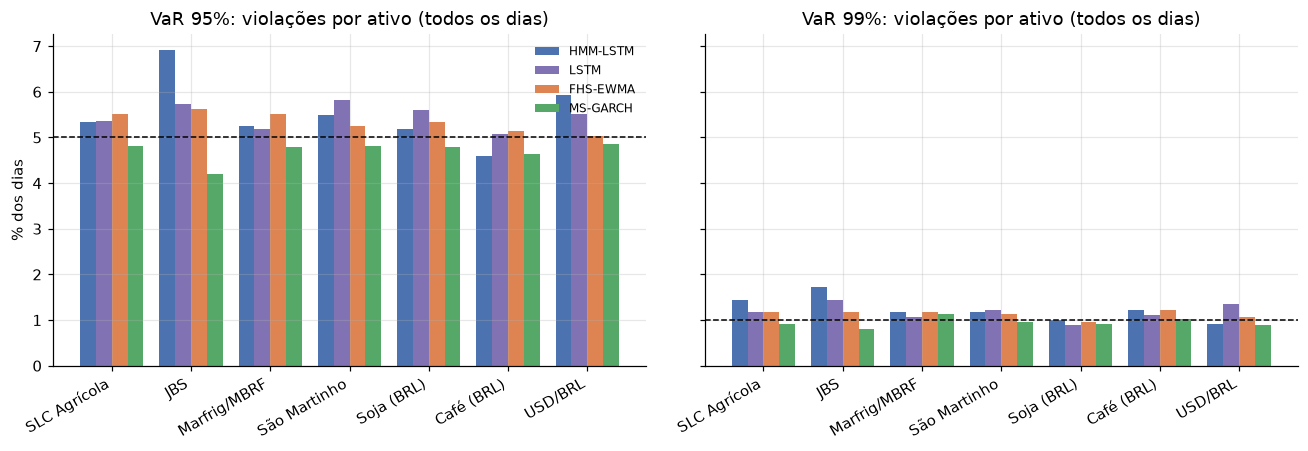

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
colors = ["#4C72B0", "#8172B3", "#DD8452", "#55A868"]
for ax, level in zip(axes, (.95, .99)):
    t = cov[(cov.segmento == "todos") & (cov.nivel == level)]
    pivot = t.pivot(index="ativo", columns="modelo", values="taxa").reindex(ASSETS.values())[ORDER] * 100
    x = np.arange(len(pivot))
    for i, model in enumerate(ORDER):
        ax.bar(x + (i - 1.5) * .2, pivot[model], .2, color=colors[i], label=model)
    ax.axhline((1 - level) * 100, color="black", ls="--", lw=1)
    ax.set_xticks(x, pivot.index, rotation=30, ha="right")
    ax.set_title(f"VaR {level:.0%}: violações por ativo (todos os dias)")
axes[0].set_ylabel("% dos dias")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_violacoes_por_ativo.png", bbox_inches="tight")

## Teste do ES por ativo (p-valor Acerbi–Székely, VaR/ES a 99%, todos os dias)

In [4]:
es = cov[(cov.segmento == "todos") & (cov.nivel == .99)].pivot(index="ativo", columns="modelo", values="es_p")
es.reindex(ASSETS.values())[ORDER].round(3)

modelo,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH
ativo,,,,
SLC Agrícola,0.001,0.013,0.014,0.625
JBS,NaN,0.001,0.001,0.727
Marfrig/MBRF,0.004,0.025,0.006,0.137
São Martinho,0.002,0.004,0.007,0.499
Soja (BRL),0.044,0.141,0.120,0.675
Café (BRL),0.005,0.056,0.020,0.403
USD/BRL,NaN,0.015,0.060,0.682


## Comparação pareada dos escores

A tabela indica o modelo com escore menor quando o teste DM detecta diferença
a 5%. Um traço indica ausência de diferença significativa.

In [5]:
pairs = ["HMM-LSTM vs LSTM", "HMM-LSTM vs MS-GARCH", "LSTM vs MS-GARCH", "FHS-EWMA vs MS-GARCH", "HMM-LSTM vs FHS-EWMA"]
def winners(score, segment, level):
    t = dm[(dm.escore == score) & (dm.segmento == segment) & (dm.nivel == level)].copy()
    t["par"] = t.a + " vs " + t.b
    t["vencedor"] = np.where(t.dm_p < .05, np.where(t.diferenca_a_menos_b > 0, t.b, t.a), "—")
    return t[t.par.isin(pairs)].pivot(index="ativo", columns="par", values="vencedor").reindex(ASSETS.values())[pairs]

for score, label in (("quantilico_var", "escore quantílico"), ("fz0_var_es", "FZ0 (VaR+ES)")):
    for level in (.95, .99):
        print(f"\n{label}, {level:.0%}, todos os dias")
        display(winners(score, "todos", level))


escore quantílico, 95%, todos os dias


par,HMM-LSTM vs LSTM,HMM-LSTM vs MS-GARCH,LSTM vs MS-GARCH,FHS-EWMA vs MS-GARCH,HMM-LSTM vs FHS-EWMA
ativo,,,,,
SLC Agrícola,—,MS-GARCH,MS-GARCH,—,—
JBS,LSTM,MS-GARCH,MS-GARCH,MS-GARCH,FHS-EWMA
Marfrig/MBRF,—,—,—,—,—
São Martinho,—,—,MS-GARCH,—,—
Soja (BRL),—,—,—,—,—
Café (BRL),—,—,—,—,FHS-EWMA
USD/BRL,—,—,—,—,—



escore quantílico, 99%, todos os dias


par,HMM-LSTM vs LSTM,HMM-LSTM vs MS-GARCH,LSTM vs MS-GARCH,FHS-EWMA vs MS-GARCH,HMM-LSTM vs FHS-EWMA
ativo,,,,,
SLC Agrícola,—,—,—,—,—
JBS,—,MS-GARCH,MS-GARCH,MS-GARCH,—
Marfrig/MBRF,—,—,—,—,—
São Martinho,—,—,—,—,—
Soja (BRL),—,—,—,—,—
Café (BRL),LSTM,—,—,—,FHS-EWMA
USD/BRL,—,—,—,—,—



FZ0 (VaR+ES), 95%, todos os dias


par,HMM-LSTM vs LSTM,HMM-LSTM vs MS-GARCH,LSTM vs MS-GARCH,FHS-EWMA vs MS-GARCH,HMM-LSTM vs FHS-EWMA
ativo,,,,,
SLC Agrícola,—,MS-GARCH,—,—,—
JBS,—,MS-GARCH,MS-GARCH,MS-GARCH,FHS-EWMA
Marfrig/MBRF,—,—,—,—,—
São Martinho,—,MS-GARCH,MS-GARCH,—,—
Soja (BRL),—,—,—,—,—
Café (BRL),—,—,—,—,—
USD/BRL,—,—,—,—,—



FZ0 (VaR+ES), 99%, todos os dias


par,HMM-LSTM vs LSTM,HMM-LSTM vs MS-GARCH,LSTM vs MS-GARCH,FHS-EWMA vs MS-GARCH,HMM-LSTM vs FHS-EWMA
ativo,,,,,
SLC Agrícola,—,—,—,—,—
JBS,—,—,MS-GARCH,MS-GARCH,—
Marfrig/MBRF,—,—,—,—,—
São Martinho,—,—,—,—,—
Soja (BRL),—,MS-GARCH,MS-GARCH,—,—
Café (BRL),LSTM,—,—,—,FHS-EWMA
USD/BRL,—,—,—,—,—


In [6]:
tally = []
for score in ("quantilico_var", "fz0_var_es"):
    for level in (.95, .99):
        w = winners(score, "todos", level)
        for pair in pairs:
            counts = w[pair].value_counts()
            tally.append({"escore": score, "nível": level, "par": pair,
                          **{k: int(v) for k, v in counts.items()}})
tally = pd.DataFrame(tally).fillna(0).set_index(["escore", "nível", "par"])
tally.astype(int)

—  LSTM  MS-GARCH  FHS-EWMA
escore         nível par                                              
quantilico_var 0.95  HMM-LSTM vs LSTM      6     1         0         0
                     HMM-LSTM vs MS-GARCH  5     0         2         0
                     LSTM vs MS-GARCH      4     0         3         0
                     FHS-EWMA vs MS-GARCH  6     0         1         0
                     HMM-LSTM vs FHS-EWMA  5     0         0         2
               0.99  HMM-LSTM vs LSTM      6     1         0         0
                     HMM-LSTM vs MS-GARCH  6     0         1         0
                     LSTM vs MS-GARCH      6     0         1         0
                     FHS-EWMA vs MS-GARCH  6     0         1         0
                     HMM-LSTM vs FHS-EWMA  6     0         0         1
fz0_var_es     0.95  HMM-LSTM vs LSTM      7     0         0         0
                     HMM-LSTM vs MS-GARCH  4     0         3         0
                     LSTM vs MS-GARCH      5     0         2         0
                     FHS-EWMA vs MS-GARCH  6     0         1         0
                     HMM-LSTM vs FHS-EWMA  6     0         0         1
               0.99  HMM-LSTM vs LSTM      6     1         0         0
                     HMM-LSTM vs MS-GARCH  6     0         1         0
                     LSTM vs MS-GARCH      5     0         2         0
                     FHS-EWMA vs MS-GARCH  6     0         1         0
                     HMM-LSTM vs FHS-EWMA  6     0         0         1

## Discussão dos resultados por ativo

As taxas totais de violações ficam próximas das nominais. O MS-GARCH tende
a apresentar menos violações a 95%, com taxas entre 4,2% e 4,9%.

A HMM-LSTM não supera significativamente o MS-GARCH em nenhum ativo.
O benchmark tem escores melhores na JBS e na SLC e, pelo FZ0, também na
São Martinho e na soja. Nos demais ativos, os testes não detectam diferença.
A HMM-LSTM também não supera a LSTM, que apresenta vantagem na JBS a 95%
e no café a 99%.

O teste de ES a 99% não rejeita o MS-GARCH em nenhum ativo. Nos casos em que
o teste é aplicável, os modelos calibrados com um ano de erros apresentam
rejeições na maior parte dos ativos. No estresse, com cerca de 290 dias
por ativo, as taxas variam e não há uma vantagem consistente entre modelos.

Na JBS, em julho e agosto de 2021, e no câmbio, em cinco dias entre 2018
e 2020, as redes produziram previsões de média elevadas e VaR negativo.
Nesses casos, até o quantil de cauda representa ganho. O teste de ES não
é aplicado aos modelos afetados nesses ativos, e o FZ0 exclui os dias com
ES não positivo. As contagens estão em `dias_excluidos_es_nao_positivo`.

A análise por ativo mantém o padrão da carteira: não há evidência de ganho
da HMM-LSTM frente à LSTM, e o MS-GARCH apresenta os resultados mais
favoráveis na avaliação da cauda extrema.